1.TAHAP PREPROCESSING 
Jumlah Missing Value per Kolom:
region                    0
crop_type                 0
soil_moisture_%           0
soil_pH                   0
rainfall_mm               0
sunlight_hours            0
irrigation_type         150
fertilizer_type           0
yield_kg_per_hectare      0
dtype: int64

Jumlah missing value setelah dihapus
region                  0
crop_type               0
soil_moisture_%         0
soil_pH                 0
rainfall_mm             0
sunlight_hours          0
irrigation_type         0
fertilizer_type         0
yield_kg_per_hectare    0
dtype: int64

Total baris duplikat yang ditemukan: 0

2. TAHAP EXPLORATORY DATA ANALYSIS (EDA)
   yield_kg_per_hectare fertilizer_type irrigation_type
1               5389.98       Inorganic       Sprinkler
2               2931.16           Mixed            Drip
3               4227.80         Organic       Sprinkler
5               4383.55           Mixed       Sprinkler
6               4501.20          

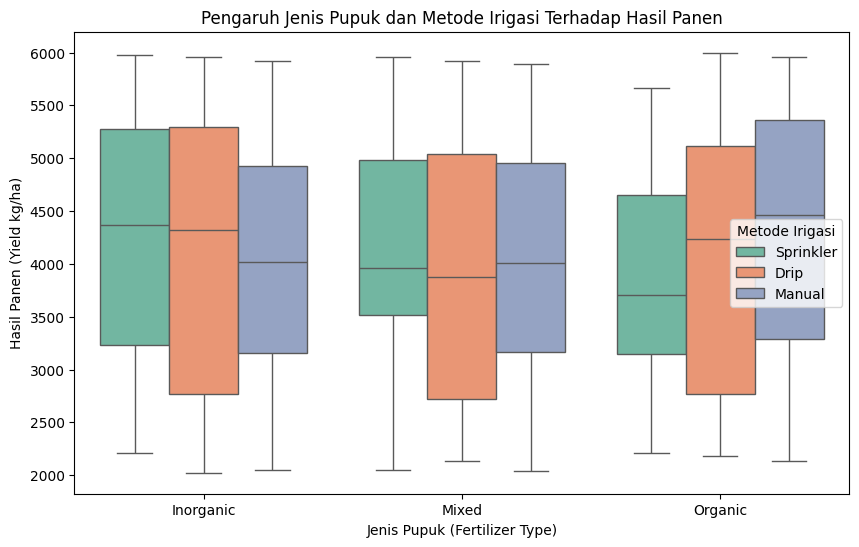


 3. TAHAP MODELING (TWO-WAY ANOVA)
Tabel Hasil ANOVA Dua Jalur:
                                             sum_sq     df         F    PR(>F)
C(fertilizer_type)                     2.936989e+05    2.0  0.107529  0.898081
C(irrigation_type)                     2.355301e+05    2.0  0.086232  0.917401
C(fertilizer_type):C(irrigation_type)  5.094390e+06    4.0  0.932576  0.445093
Residual                               4.656956e+08  341.0       NaN       NaN

 4. TAHAP VALIDITAS (UJI ASUMSI)

--- Uji Normalitas (Shapiro-Wilk Test) ---
Statistik Uji: 0.951, P-value: 0.000
Keputusan: Tolak H0. Residual tidak terdistribusi normal.


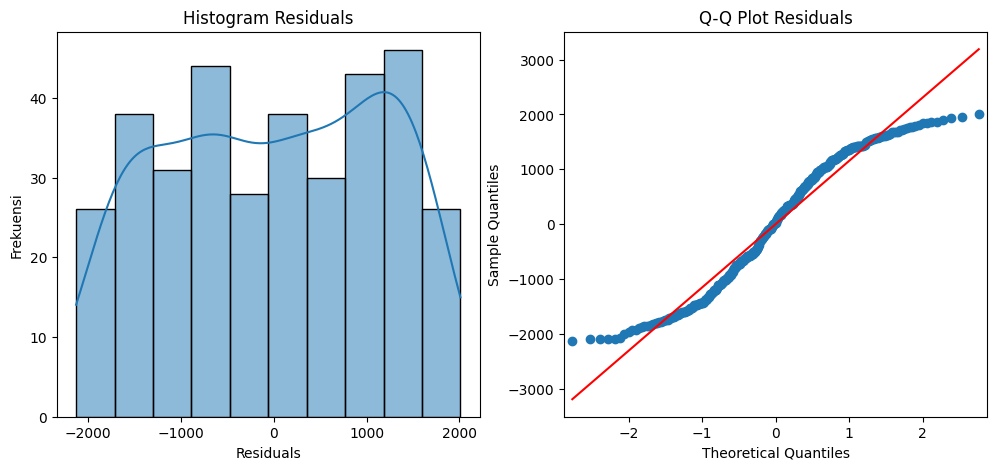


---- Uji Homogenitas (Levene's Test)----
P-value: 0.5532
 Keputusan: Gagal menolak H0. Varians antar kelompok homogen

--- Uji Additivitas ---
P-value: 0.4451
Keputusan: Gagal menolak H0. Tidak ada interaksi yang signifikan


In [8]:
# ==============================================================================
# IMPORT LIBRARY
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import levene, shapiro
import statsmodels.api as sm
from statsmodels.formula.api import ols

# ==========================================
# PREPROCESSING
# ==========================================
print('1.TAHAP PREPROCESSING ')
df = pd.read_csv('/content/Smart_Farming_Crop_Yield_2024-selected-columns.csv')

# Cek Missing Value
print('Jumlah Missing Value per Kolom:')
print(df.isnull().sum())
print(f'\nJumlah missing value setelah dihapus')
df_clean = df.dropna()
print(df_clean.isnull().sum())

#  Cek duplikat
total_duplicates = df.duplicated().sum()
print(f'\nTotal baris duplikat yang ditemukan: {total_duplicates}')

# ==============================================================================
# EDA (Eksplorasi Data)
# ==============================================================================
print('\n2. TAHAP EXPLORATORY DATA ANALYSIS (EDA)')
selected_cols = ['yield_kg_per_hectare', 'fertilizer_type', 'irrigation_type']
df_subset = df_clean[selected_cols]
print(df_subset.head())

print('\nINFORMASI DATA:')
print(df_subset.info())

print('STATISTIK DESKRIPTIF:')
print(df_subset.describe(include='all'))

# Visualisasi Interaksi (Boxplot)
plt.figure(figsize=(10, 6))
sns.boxplot(
    x='fertilizer_type', y='yield_kg_per_hectare', hue='irrigation_type', data=df_clean, palette='Set2'
)
plt.title(
    'Pengaruh Jenis Pupuk dan Metode Irigasi Terhadap Hasil Panen'
)
plt.xlabel('Jenis Pupuk (Fertilizer Type)')
plt.ylabel('Hasil Panen (Yield kg/ha)')
plt.legend(title='Metode Irigasi')
plt.show()

# ==============================================================================
#  MODELING (TWO-WAY ANOVA DENGAN INTERAKSI)
# ==============================================================================
print('\n 3. TAHAP MODELING (TWO-WAY ANOVA)')

# Membuat model OLS untuk ANOVA Dua Jalur
model = ols(
    'yield_kg_per_hectare ~ C(fertilizer_type) + C(irrigation_type) + C(fertilizer_type):C(irrigation_type)',
    data=df_clean,
).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print('Tabel Hasil ANOVA Dua Jalur:')
print(anova_table)


# ==============================================================================
# VALIDITAS (UJI ASUMSI)
# ==============================================================================
print('\n 4. TAHAP VALIDITAS (UJI ASUMSI)')
residuals = model.resid

# Uji Normalitas (Shapiro-Wilk)
print("\n--- Uji Normalitas (Shapiro-Wilk Test) ---")
stat, p = shapiro(residuals)
print(f'Statistik Uji: {stat:.3f}, P-value: {p:.3f}')

if p > 0.05:
    print('Keputusan: Gagal menolak H0. Residual terdistribusi normal.')
else:
    print('Keputusan: Tolak H0. Residual tidak terdistribusi normal.')
fig, ax = plt.subplots(1,2, figsize=(12,5))
sns.histplot(residuals, kde=True, ax=ax[0])
ax[0].set_title('Histogram Residuals')
ax[0].set_xlabel('Residuals')
ax[0].set_ylabel('Frekuensi')

sm.qqplot(residuals, line='s', ax=ax[1])
ax[1].set_title('Q-Q Plot Residuals')

plt.show()


# Uji Homogenitas Varians (Levene\'s Test)
groups = df_clean['fertilizer_type'].astype(str) + '_' + df_clean['irrigation_type'].astype(str)
stat_lev, p_val_lev = levene(
    *[ group['yield_kg_per_hectare'].values
        for name, group in df_clean.groupby(groups)])

print("\n---- Uji Homogenitas (Levene\'s Test)----")
print(f"P-value: {p_val_lev:.4f}")
if p_val_lev > 0.05:
  print(
      ' Keputusan: Gagal menolak H0. Varians antar kelompok homogen')
else:
  print(
      ' Keputusan: Tolak H0. Varians antar kelompok tidak homogen (Heteroskedastisitas)')

# Uji Additivitas
p_val_interaction = anova_table.loc['C(fertilizer_type):C(irrigation_type)', 'PR(>F)']
print('\n--- Uji Additivitas ---')
print(f'P-value: {p_val_interaction:.4f}')
if p_val_interaction > 0.05:
  print(
      'Keputusan: Gagal menolak H0. Tidak ada interaksi yang signifikan')
else:
  print(
      'Keputusan: Tolak H0. Terdapat interaksi yang signifikan' )
